# ПР2. Разведочный анализ данных (300W)

Анализ только на исходной части `data/interim/initial.csv` (360 снимков).
Порции из `data/incoming` не трогаем, они нужны позже для проверки дрейфа.

In [1]:
import hashlib
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR = ROOT / "data/raw/300w"
FIG = ROOT / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)


def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", dpi=130)


df = pd.read_csv(ROOT / "data/interim/initial.csv")
df.shape

(360, 140)

## 1. Структура набора

In [2]:
print("строк:", len(df), " столбцов:", df.shape[1])
print("память, КБ:", round(df.memory_usage(deep=True).sum() / 1024))
print(df.dtypes.value_counts().to_string())
df.iloc[:5, :10]

строк: 360  столбцов: 140
память, КБ: 405
float64    136
str          2
int64        2


,image,subset,width,height,x1,y1,x2,y2,x3,y3
0,01_Indoor/indoor_001.png,indoor,1004,753,446.000,91.000,449.459,119.344,450.957,150.614
1,01_Indoor/indoor_003.png,indoor,1200,800,366.000,322.304,370.151,383.263,373.595,442.898
2,01_Indoor/indoor_004.png,indoor,930,523,307.000,263.693,312.176,292.678,321.195,329.394
3,01_Indoor/indoor_005.png,indoor,650,454,181.512,175.594,174.000,214.573,174.211,253.350
4,01_Indoor/indoor_008.png,indoor,1000,750,309.477,313.483,305.000,355.601,307.758,406.453


In [3]:
cols = pd.DataFrame([
    ("image", "str", "путь к картинке относительно data/raw/300w", "идентификатор"),
    ("subset", "str (категория)", "условия съемки: indoor / outdoor", "служебный"),
    ("width", "int", "ширина изображения, px", "признак"),
    ("height", "int", "высота изображения, px", "признак"),
    ("x1..x68", "float", "координата x точки i по разметке 300W, px", "цель"),
    ("y1..y68", "float", "координата y точки i (ось вниз), px", "цель"),
], columns=["столбец", "тип", "смысл", "роль"])
cols

,столбец,тип,смысл,роль
0,image,str,путь к картинке относительно data/raw/300w,идентификатор
1,subset,str (категория),условия съемки: indoor / outdoor,служебный
2,width,int,"ширина изображения, px",признак
3,height,int,"высота изображения, px",признак
4,x1..x68,float,"координата x точки i по разметке 300W, px",цель
5,y1..y68,float,"координата y точки i (ось вниз), px",цель


In [4]:
df[["width", "height"]].describe().T

,count,mean,std,min,25%,50%,75%,max
width,360.0,1785.283,1238.714,168.0,800.00,1306.5,2560.00,5616.0
height,360.0,1298.636,854.463,121.0,639.75,1024.0,1850.25,4800.0


## 2. Целевая переменная

Из 68 точек собираем 8 точек проекта. Нормировка: начало координат в середине
между центрами глаз, масштаб = межзрачковое расстояние (IOD). Поворот не убираем.

In [5]:
def pt(i):
    return df[[f"x{i}", f"y{i}"]].to_numpy()


def mean_pt(ids):
    return np.mean([pt(i) for i in ids], axis=0)


P = {
    "eye_l": mean_pt(range(37, 43)),
    "eye_r": mean_pt(range(43, 49)),
    "nose_tip": pt(31),
    "nose_l": pt(32),
    "nose_r": pt(36),
    "mouth_l": pt(49),
    "mouth_r": pt(55),
    "chin": pt(9),
}
RU = {
    "eye_l": "центр лев. глаза", "eye_r": "центр прав. глаза", "nose_tip": "кончик носа",
    "nose_l": "крыло носа лев.", "nose_r": "крыло носа прав.",
    "mouth_l": "угол рта лев.", "mouth_r": "угол рта прав.", "chin": "подбородок",
}

center = (P["eye_l"] + P["eye_r"]) / 2
iod = np.linalg.norm(P["eye_r"] - P["eye_l"], axis=1)
N = {k: (v - center) / iod[:, None] for k, v in P.items()}

# все 68 точек в тех же координатах, для средней формы
X = df[[f"x{i}" for i in range(1, 69)]].to_numpy()
Y = df[[f"y{i}" for i in range(1, 69)]].to_numpy()
X68 = (X - center[:, [0]]) / iod[:, None]
Y68 = (Y - center[:, [1]]) / iod[:, None]
print("IOD, px: min %.1f, медиана %.1f, max %.1f" % (iod.min(), np.median(iod), iod.max()))

IOD, px: min 29.3, медиана 87.4, max 570.1


subset
indoor     180
outdoor    180 
доли: {'indoor': 0.5, 'outdoor': 0.5}


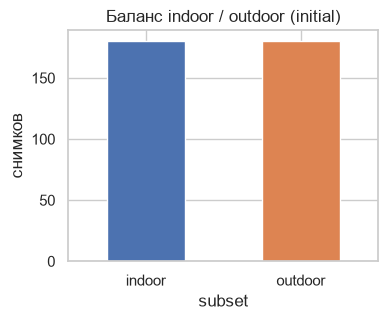

In [6]:
bal = df["subset"].value_counts()
print(bal.to_string(), "\nдоли:", (bal / len(df)).round(3).to_dict())

fig, ax = plt.subplots(figsize=(4, 3))
bal.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"], rot=0)
ax.set_title("Баланс indoor / outdoor (initial)")
ax.set_ylabel("снимков")
save(fig, "01_subset_balance.png")

In [7]:
spread = pd.DataFrame({
    "точка": [RU[k] for k in N],
    "mean_x": [N[k][:, 0].mean() for k in N],
    "mean_y": [N[k][:, 1].mean() for k in N],
    "std_x": [N[k][:, 0].std() for k in N],
    "std_y": [N[k][:, 1].std() for k in N],
    # среднее расстояние до средней позиции точки, в долях IOD
    "ср_откл": [np.linalg.norm(N[k] - N[k].mean(0), axis=1).mean() for k in N],
}).set_index("точка")
spread

,mean_x,mean_y,std_x,std_y,ср_откл
точка,,,,,
центр лев. глаза,-0.493,0.011,0.012,0.083,0.065
центр прав. глаза,0.493,-0.011,0.012,0.083,0.065
кончик носа,0.015,0.511,0.234,0.191,0.262
крыло носа лев.,-0.259,0.683,0.160,0.144,0.186
крыло носа прав.,0.279,0.677,0.161,0.146,0.185
угол рта лев.,-0.444,1.127,0.200,0.198,0.241
угол рта прав.,0.494,1.100,0.198,0.208,0.241
подбородок,0.062,1.952,0.309,0.299,0.364


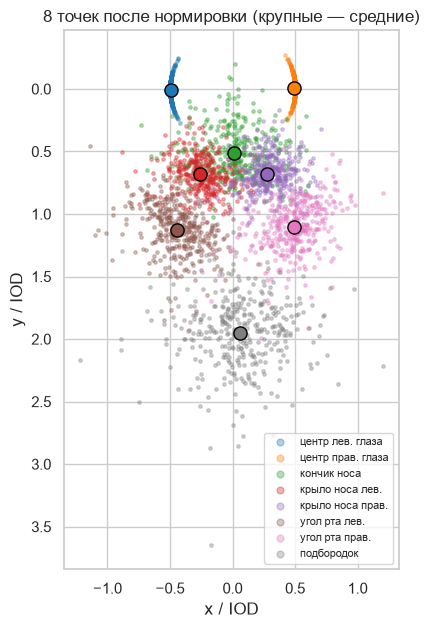

In [8]:
colors = dict(zip(N, sns.color_palette("tab10", 8)))
fig, ax = plt.subplots(figsize=(6.5, 7))
for k, v in N.items():
    ax.scatter(v[:, 0], v[:, 1], s=6, alpha=0.35, color=colors[k], label=RU[k])
    ax.scatter(*v.mean(0), s=90, color=colors[k], edgecolor="black", zorder=3)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_xlabel("x / IOD")
ax.set_ylabel("y / IOD")
ax.set_title("8 точек после нормировки (крупные — средние)")
ax.legend(fontsize=8, markerscale=2, loc="lower right")
save(fig, "02_points_normalized.png")

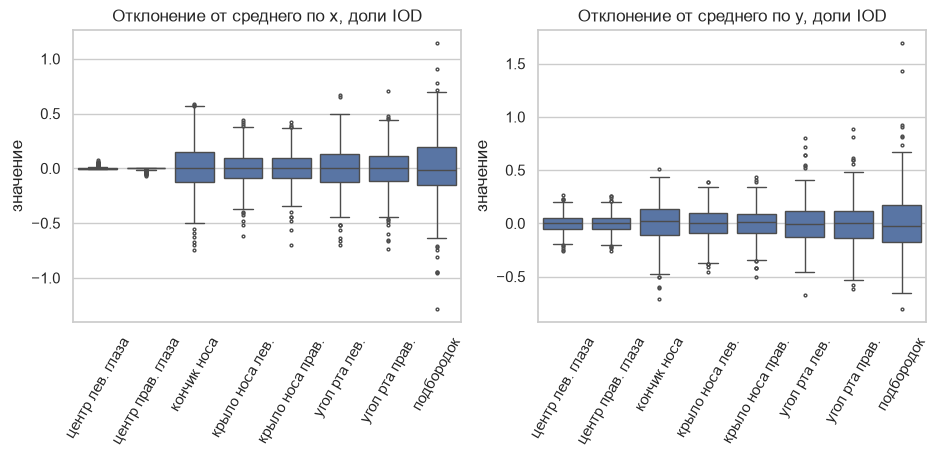

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
long = pd.concat([pd.DataFrame({"точка": RU[k], "ось": ax_, "значение": N[k][:, j] - N[k][:, j].mean()})
                  for k in N for j, ax_ in enumerate("xy")])
for a, ax_ in zip(axes, "xy"):
    sns.boxplot(data=long[long["ось"] == ax_], x="точка", y="значение", ax=a, fliersize=2)
    a.set_title(f"Отклонение от среднего по {ax_}, доли IOD")
    a.tick_params(axis="x", rotation=60)
    a.set_xlabel("")
save(fig, "03_points_spread.png")

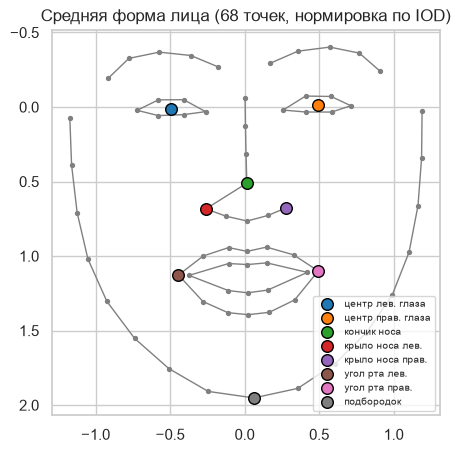

In [10]:
mx, my = X68.mean(0), Y68.mean(0)
groups = [range(0, 17), range(17, 22), range(22, 27), range(27, 31), range(30, 36),
          list(range(36, 42)) + [36], list(range(42, 48)) + [42],
          list(range(48, 60)) + [48], list(range(60, 68)) + [60]]
fig, ax = plt.subplots(figsize=(5, 6))
for g in groups:
    g = list(g)
    ax.plot(mx[g], my[g], color="gray", lw=1)
ax.scatter(mx, my, s=8, color="gray")
for k in N:
    ax.scatter(*N[k].mean(0), s=70, color=colors[k], edgecolor="black", zorder=3, label=RU[k])
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_title("Средняя форма лица (68 точек, нормировка по IOD)")
ax.legend(fontsize=7, loc="lower right")
save(fig, "04_mean_shape.png")

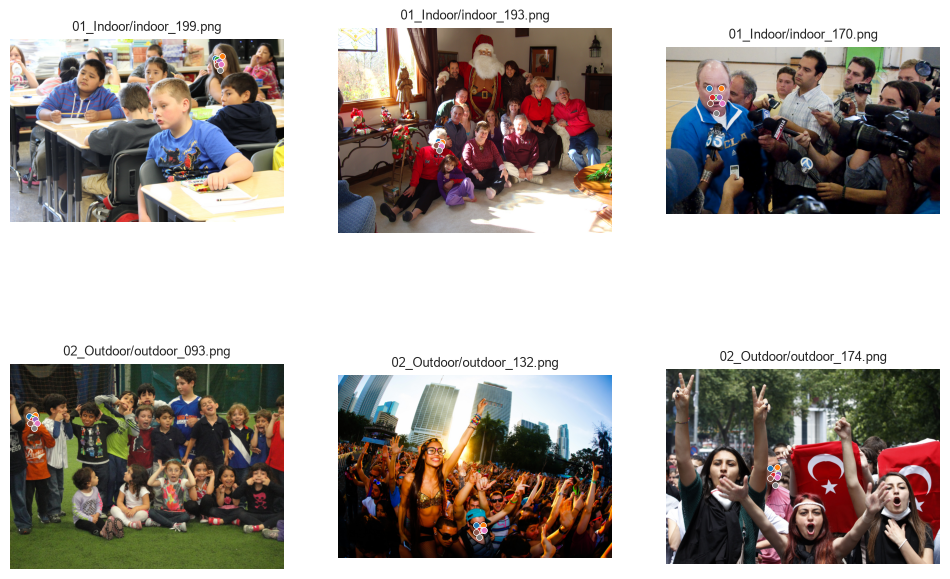

In [11]:
# несколько снимков с 8 точками, просто глазами посмотреть на данные
sample = df.groupby("subset").sample(3, random_state=1).index
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for a, i in zip(axes.ravel(), sample):
    with Image.open(IMG_DIR / df.at[i, "image"]) as im:
        a.imshow(im)
    for k in P:
        a.scatter(*P[k][i], s=18, color=colors[k], edgecolor="white", linewidths=0.5)
    a.set_title(df.at[i, "image"], fontsize=9)
    a.axis("off")
save(fig, "05_examples.png")

**Итого по цели.** 360 снимков, indoor и outdoor ровно 180/180. Центры глаз после нормировки лежат
в ±0.5 по x и разбросаны только по y (std 0.08 IOD) — это наклон головы, который мы не убирали.
Сильнее всего гуляют подбородок (среднее отклонение 0.36 IOD) и кончик носа (0.26),
у носа большой разброс по x (std 0.23) из-за поворота головы. Средняя форма симметричная,
подбородок в среднем на 1.95 IOD ниже линии глаз.

## 3. Качество данных

In [12]:
print("пропусков всего:", int(df.isna().sum().sum()))
print("полных дубликатов строк:", int(df.duplicated().sum()))
print("повторов имени файла:", int(df["image"].duplicated().sum()))
coord_cols = [c for c in df.columns if c[0] in "xy" and c[1:].isdigit()]
print("одинаковая разметка (все 136 координат):", int(df.duplicated(coord_cols).sum()))
print("отрицательных координат:", int((df[coord_cols] < 0).sum().sum()))

пропусков всего: 0
полных дубликатов строк: 0
повторов имени файла: 0
одинаковая разметка (все 136 координат): 0
отрицательных координат: 0


In [13]:
# хэши картинок: точные копии (sha256) и почти одинаковые (dHash 8x8)
def file_sha(p):
    return hashlib.sha256(p.read_bytes()).hexdigest()


def dhash(p, size=8):
    with Image.open(p) as im:
        g = np.asarray(im.convert("L").resize((size + 1, size), Image.LANCZOS), dtype=float)
    return (g[:, 1:] > g[:, :-1]).ravel()


paths = [IMG_DIR / p for p in df["image"]]
df["sha"] = [file_sha(p) for p in paths]
H = np.array([dhash(p) for p in paths])
real_size = [Image.open(p).size for p in paths]

print("одинаковых файлов по sha256:", int(df["sha"].duplicated().sum()))
dist = (H[:, None, :] != H[None, :, :]).sum(-1)
iu = np.triu_indices(len(df), 1)
print("пар с dHash-расстоянием <= 4 из 64:", int((dist[iu] <= 4).sum()))
print("размер в CSV не совпал с файлом:",
      sum((w, h) != s for w, h, s in zip(df.width, df.height, real_size)))

# склеиваем похожие картинки в группы
_, df["photo_grp"] = connected_components(csr_matrix(dist <= 4))
grp = df[df.duplicated("photo_grp", keep=False)]
print(f"групп одного фото: {grp.photo_grp.nunique()}, снимков в них: {len(grp)}, "
      f"«лишних» копий: {len(grp) - grp.photo_grp.nunique()}")
print("в каждой группе один размер кадра:",
      grp.groupby("photo_grp").apply(lambda g: g.width.nunique() == 1 and g.height.nunique() == 1).all())

# разные ли лица размечены: смотрим сдвиг центра лица внутри группы
fc = np.c_[X.mean(1), Y.mean(1)]
shift = grp.groupby("photo_grp").apply(
    lambda g: np.linalg.norm(fc[g.index][:, None] - fc[g.index][None], axis=-1).max() / g.width.iloc[0])
print("сдвиг центра лица внутри группы / ширина кадра: min %.3f, медиана %.3f" % (shift.min(), shift.median()))
grp.groupby("photo_grp").image.apply(list).head(5)

одинаковых файлов по sha256: 11
пар с dHash-расстоянием <= 4 из 64: 124
размер в CSV не совпал с файлом: 0
групп одного фото: 53, снимков в них: 135, «лишних» копий: 82
в каждой группе один размер кадра: True
сдвиг центра лица внутри группы / ширина кадра: min 0.106, медиана 0.405


photo_grp
34    [01_Indoor/indoor_061.png, 01_Indoor/indoor_06...
73    [01_Indoor/indoor_133.png, 01_Indoor/indoor_13...
77    [01_Indoor/indoor_144.png, 01_Indoor/indoor_14...
78    [01_Indoor/indoor_146.png, 01_Indoor/indoor_14...
79    [01_Indoor/indoor_149.png, 01_Indoor/indoor_15...
Name: image, dtype: object

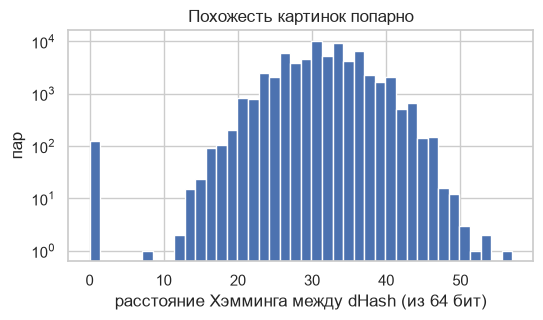

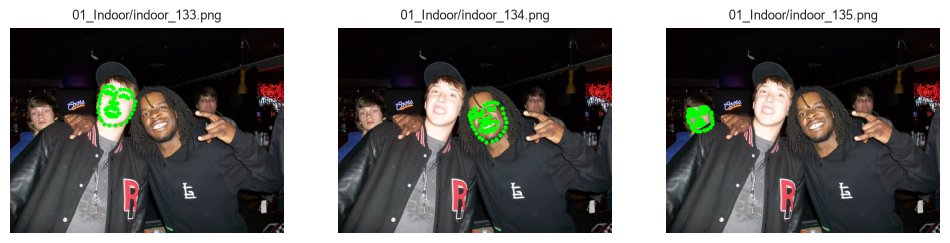

In [14]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(dist[iu], bins=40, color="#4C72B0")
ax.set_xlabel("расстояние Хэмминга между dHash (из 64 бит)")
ax.set_ylabel("пар")
ax.set_title("Похожесть картинок попарно")
ax.set_yscale("log")
save(fig, "06_dhash_distances.png")

# пример: одна фотография, на ней размечены разные лица
g0 = grp.groupby("photo_grp").filter(lambda g: len(g) >= 3).photo_grp.iloc[0]
ids = df.index[df.photo_grp == g0][:3]
fig, axes = plt.subplots(1, len(ids), figsize=(4 * len(ids), 3.5))
for a, i in zip(axes, ids):
    with Image.open(IMG_DIR / df.at[i, "image"]) as im:
        a.imshow(im)
    a.scatter(X[i], Y[i], s=4, color="lime")
    a.set_title(df.at[i, "image"], fontsize=9)
    a.axis("off")
save(fig, "06b_same_photo.png")

In [15]:
W, Hh = df["width"].to_numpy()[:, None], df["height"].to_numpy()[:, None]
out68 = (X < 0) | (X > W - 1) | (Y < 0) | (Y > Hh - 1)
ids8 = [31, 32, 36, 49, 55, 9] + list(range(37, 49))
out8 = out68[:, [i - 1 for i in ids8]]
print("снимков, где хоть одна из 68 точек вне кадра:", int(out68.any(1).sum()))
print("снимков, где вне кадра точка, нужная для 8 точек проекта:", int(out8.any(1).sum()))
over = np.maximum.reduce([-X, X - (W - 1), -Y, Y - (Hh - 1)])
print("максимальный выход за край, px: %.1f" % over.max())
bad_pts = pd.Series(out68.sum(0), index=range(1, 69))
print("какие точки чаще вылезают:", bad_pts[bad_pts > 0].to_dict())
df.loc[out68.any(1), ["image", "subset", "width", "height"]].assign(
    n_out=out68.sum(1)[out68.any(1)], max_px=over.max(1)[out68.any(1)].round(1))

снимков, где хоть одна из 68 точек вне кадра: 5
снимков, где вне кадра точка, нужная для 8 точек проекта: 3
максимальный выход за край, px: 1.5
какие точки чаще вылезают: {8: 2, 9: 3, 10: 1, 16: 1, 17: 1}


,image,subset,width,height,n_out,max_px
44,01_Indoor/indoor_078.png,indoor,500,361,1,1.5
53,01_Indoor/indoor_093.png,indoor,960,544,1,0.9
146,01_Indoor/indoor_255.png,indoor,168,121,1,1.0
287,02_Outdoor/outdoor_178.png,outdoor,1400,1024,2,1.3
330,02_Outdoor/outdoor_249.png,outdoor,184,148,3,1.2


In [16]:
print("IOD == 0:", int((iod == 0).sum()))
for thr in (20, 30, 40):
    print(f"IOD < {thr} px:", int((iod < thr).sum()))
iod_rel = iod / df["width"].to_numpy()
print("IOD / ширина кадра: min %.3f, 1%% квантиль %.3f" % (iod_rel.min(), np.quantile(iod_rel, 0.01)))

swap = pd.Series({
    "глаза (лев. правее прав.)": int((P["eye_l"][:, 0] >= P["eye_r"][:, 0]).sum()),
    "крылья носа 32 правее 36": int((P["nose_l"][:, 0] >= P["nose_r"][:, 0]).sum()),
    "уголки рта 49 правее 55": int((P["mouth_l"][:, 0] >= P["mouth_r"][:, 0]).sum()),
    "подбородок выше носа": int((P["chin"][:, 1] <= P["nose_tip"][:, 1]).sum()),
    "рот выше носа": int((((P["mouth_l"][:, 1] + P["mouth_r"][:, 1]) / 2) <= P["nose_tip"][:, 1]).sum()),
})
swap

IOD == 0: 0
IOD < 20 px: 0
IOD < 30 px: 2
IOD < 40 px: 20
IOD / ширина кадра: min 0.011, 1% квантиль 0.013


глаза (лев. правее прав.)    0
крылья носа 32 правее 36     0
уголки рта 49 правее 55      0
подбородок выше носа         0
рот выше носа                0
dtype: int64

In [17]:
# рамка лица по 68 точкам и выбросы по ее размеру
bx0, bx1, by0, by1 = X.min(1), X.max(1), Y.min(1), Y.max(1)
df["bbox_w"], df["bbox_h"] = bx1 - bx0, by1 - by0
df["face_frac"] = df.bbox_w * df.bbox_h / (df.width * df.height)
df["face_px"] = np.sqrt(df.bbox_w * df.bbox_h)

def iqr_out(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
    return (s < lo) | (s > hi), lo, hi

# распределения сильно скошены, поэтому IQR считаем по логарифму
for col in ("face_px", "face_frac"):
    m, lo, hi = iqr_out(np.log(df[col]))
    print(f"{col}: выбросов по IQR(log) {int(m.sum())} (ниже {int((np.log(df[col]) < lo).sum())}), "
          f"границы [{np.exp(lo):.4f}; {np.exp(hi):.3f}], min {df[col].min():.4f}, max {df[col].max():.3f}")
# пропорции рамки тоже смотрим: слишком вытянутая = подозрение на ошибку разметки
ar = df.bbox_w / df.bbox_h
m, lo, hi = iqr_out(ar)
print(f"bbox w/h: выбросов {int(m.sum())}, диапазон {ar.min():.2f}..{ar.max():.2f}")

face_px: выбросов по IQR(log) 1 (ниже 0), границы [47.5999; 1014.000], min 68.8511, max 1422.852
face_frac: выбросов по IQR(log) 0 (ниже 0), границы [0.0002; 6.842], min 0.0008, max 0.537
bbox w/h: выбросов 10, диапазон 0.53..1.34


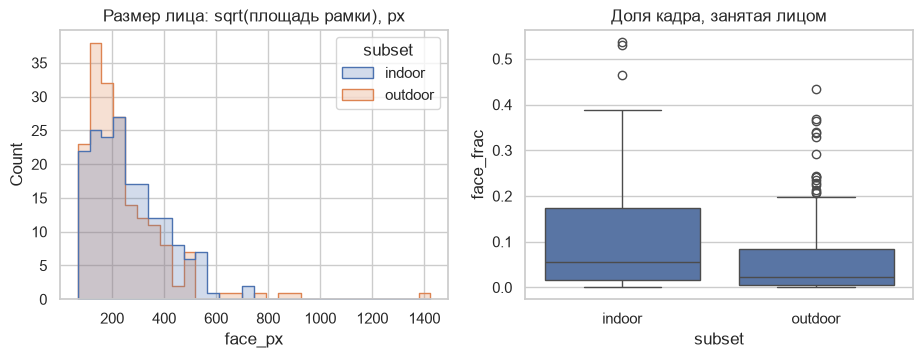

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(data=df, x="face_px", hue="subset", bins=30, ax=axes[0], element="step")
axes[0].set_title("Размер лица: sqrt(площадь рамки), px")
sns.boxplot(data=df, x="subset", y="face_frac", ax=axes[1])
axes[1].set_title("Доля кадра, занятая лицом")
save(fig, "07_face_size.png")

**Итого по качеству.**
- Пропусков, дубликатов строк и одинаковой разметки нет.
- 11 файлов совпадают по sha256, а по dHash набирается 53 группы (135 снимков, 82 «лишних»).
  Это не ошибки: в 300W одно фото с несколькими людьми лежит отдельными файлами, на каждом размечено
  свое лицо (центры лиц внутри группы разнесены минимум на 0.11 ширины кадра). Но при разбиении на
  train/val такие снимки надо держать в одной части, иначе модель увидит тот же фон и освещение.
- Точки за кадром: 5 снимков, максимум на 1.5 px, в основном подбородок (точки 8–10).
  Это погрешность разметки у края, достаточно обрезать координаты по границе.
- Межзрачковое расстояние нигде не нулевое, минимум 29.3 px; меньше 30 px — 2 снимка, меньше 40 px — 20.
- Перепутанных сторон нет (глаза, крылья носа, уголки рта, подбородок ниже носа).
- По размеру лица в логарифме выброс один (самое крупное лицо, 1423 px), по пропорциям рамки 10
  (w/h от 0.53 до 1.34, это сильные повороты).

## 4. Признаки и связи

In [19]:
def dist2(a, b):
    return np.linalg.norm(a - b, axis=1)

feat = pd.DataFrame({
    "subset": df["subset"],
    "width": df["width"],
    "height": df["height"],
    "megapix": df.width * df.height / 1e6,
    "aspect": df.width / df.height,
    "face_frac": df["face_frac"],
    "face_px": df["face_px"],
    "iod_px": iod,
    # поворот головы: смещение кончика носа от середины глаз по x
    "yaw": (P["nose_tip"][:, 0] - center[:, 0]) / iod,
    # наклон линии глаз, градусы
    "roll_deg": np.degrees(np.arctan2(P["eye_r"][:, 1] - P["eye_l"][:, 1],
                                      P["eye_r"][:, 0] - P["eye_l"][:, 0])),
    "mouth_open": dist2(pt(63), pt(67)) / iod,
    "nose_idx": dist2(P["nose_l"], P["nose_r"]) / iod,
    "mouth_idx": dist2(P["mouth_l"], P["mouth_r"]) / iod,
    # асимметрия: насколько кончик носа ближе к одному глазу, чем к другому
    "asym": (dist2(P["nose_tip"], P["eye_l"]) - dist2(P["nose_tip"], P["eye_r"])) / iod,
})
feat["abs_yaw"] = feat["yaw"].abs()
num = feat.drop(columns="subset")
num.describe().T

,count,mean,std,min,25%,50%,75%,max
width,360.0,1785.283,1238.714,1.680e+02,800.000,1306.500,2560.000,5616.000
height,360.0,1298.636,854.463,1.210e+02,639.750,1024.000,1850.250,4800.000
megapix,360.0,3.324,4.134,2.033e-02,0.517,1.369,4.485,21.026
aspect,360.0,1.376,0.295,6.355e-01,1.333,1.367,1.502,2.702
face_frac,360.0,0.083,0.102,8.287e-04,0.009,0.039,0.128,0.537
face_px,360.0,253.981,150.870,6.885e+01,149.888,222.249,322.015,1422.852
iod_px,360.0,105.391,65.729,2.929e+01,59.330,87.419,136.612,570.072
yaw,360.0,0.015,0.235,-7.293e-01,-0.113,0.020,0.167,0.604
roll_deg,360.0,-1.253,9.735,-3.312e+01,-7.157,-1.089,4.591,29.988
mouth_open,360.0,0.194,0.224,0.000e+00,0.000,0.139,0.288,1.337


In [20]:
feat.groupby("subset")[["megapix", "face_frac", "iod_px", "yaw", "abs_yaw", "roll_deg",
                        "mouth_open", "nose_idx", "mouth_idx"]].median().T

subset,indoor,outdoor
megapix,0.875,2.049
face_frac,0.055,0.022
iod_px,95.574,85.105
yaw,0.014,0.029
abs_yaw,0.140,0.153
roll_deg,-1.042,-1.089
mouth_open,0.134,0.156
nose_idx,0.544,0.548
mouth_idx,0.929,0.950


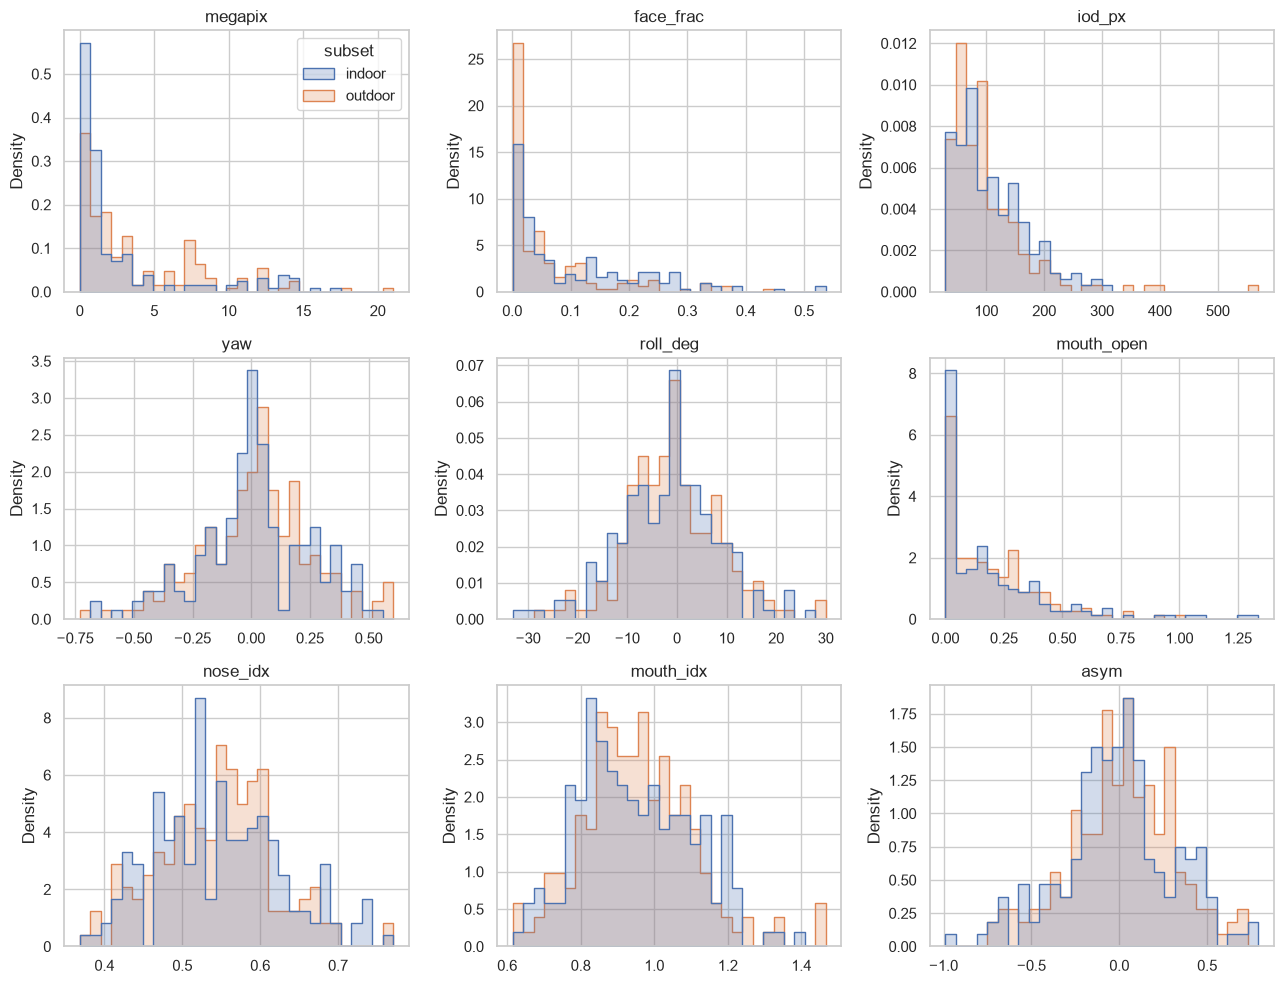

In [21]:
show = ["megapix", "face_frac", "iod_px", "yaw", "roll_deg", "mouth_open", "nose_idx", "mouth_idx", "asym"]
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for a, c in zip(axes.ravel(), show):
    sns.histplot(data=feat, x=c, hue="subset", bins=30, ax=a, element="step", stat="density",
                 common_norm=False, legend=(c == show[0]))
    a.set_title(c)
    a.set_xlabel("")
fig.tight_layout()
save(fig, "08_features_hist.png")

yaw ~ roll: rho=-0.124
yaw ~ asym: rho=0.911


width       megapix      0.984
height      megapix      0.983
face_px     iod_px       0.978
width       height       0.938
yaw         asym         0.911
width       face_frac   -0.760
megapix     face_frac   -0.739
height      face_frac   -0.695
nose_idx    mouth_idx    0.497
face_frac   iod_px       0.492
            face_px      0.476
mouth_open  mouth_idx    0.342
dtype: float64

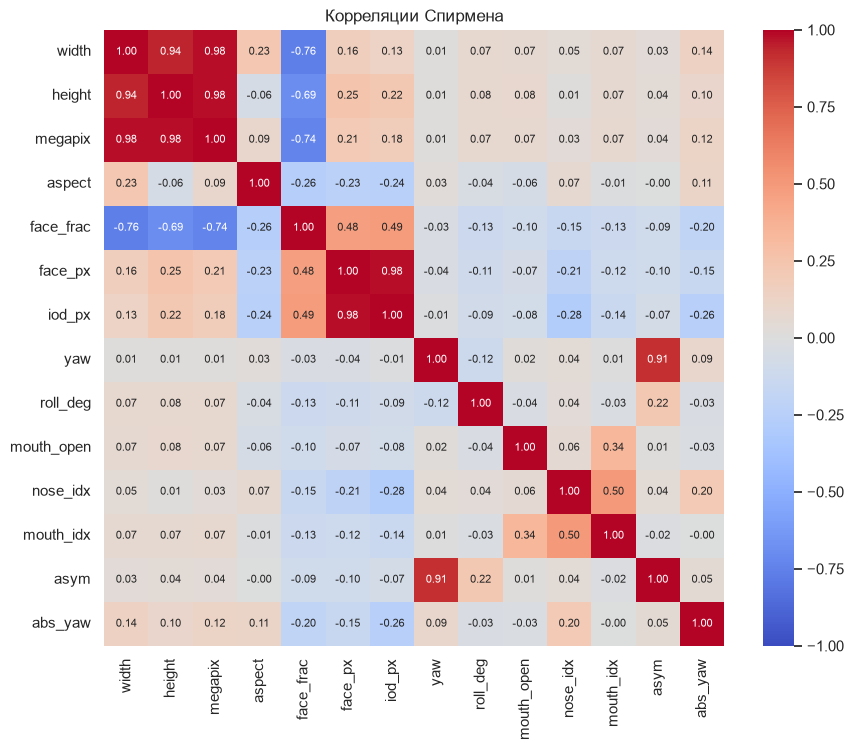

In [22]:
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax,
            annot_kws={"size": 8})
ax.set_title("Корреляции Спирмена")
save(fig, "09_corr.png")

# самые сильные пары, кроме очевидных (одно и то же разными словами)
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print("yaw ~ roll: rho=%.3f" % corr.at["yaw", "roll_deg"])
print("yaw ~ asym: rho=%.3f" % corr.at["yaw", "asym"])
pairs.head(12)

**Итого по признакам.**
- Размер кадра очень разный: от 168×121 до 5616×4800, медиана 1.4 Мп. Outdoor-кадры крупнее (2.0 против 0.9 Мп).
- Лицо занимает от 0.08% до 54% кадра, медиана 3.9%. Доля кадра почти целиком определяется размером
  картинки (rho = −0.74 с мегапикселями), а не размером лица.
- IOD в пикселях дублирует размер лица (rho = 0.98), второй признак из пары лишний.
- Индекс асимметрии «нос–глаза» почти повторяет yaw (rho = 0.91), то есть сейчас он меряет поворот головы,
  а не асимметрию лица. Связь yaw с наклоном (roll) слабая (rho = −0.12).
- Индексы носа и рта связаны между собой (rho = 0.50), индекс рта растет с открытостью рта (rho = 0.34).

## 5. Признаки, которых не будет при предсказании, и утечки цели

**Рамка лица по точкам.** В разметке рамку строим из самих 68 точек, а в эксплуатации ее даст
детектор лица. Проверим, насколько такая рамка «подсказывает» ответ.

In [23]:
# кто задает края рамки
lowest = (Y.argmax(1) + 1)
print("нижний край рамки задает точка 9 (подбородок):", f"{(lowest == 9).mean():.1%}",
      "| одна из 8-10:", f"{np.isin(lowest, [8, 9, 10]).mean():.1%}")
left_e, right_e = X.argmin(1) + 1, X.argmax(1) + 1
print("левый край задает точка 1-3:", f"{np.isin(left_e, [1, 2, 3]).mean():.1%}",
      "| правый край 15-17:", f"{np.isin(right_e, [15, 16, 17]).mean():.1%}")

нижний край рамки задает точка 9 (подбородок): 63.3% | одна из 8-10: 94.7%
левый край задает точка 1-3: 79.7% | правый край 15-17: 77.2%


In [24]:
# простейший базовый прогноз: средняя форма 8 точек в координатах рамки.
# с идеальной рамкой (по точкам) и с рамкой, сдвинутой как у реального детектора (~10%)
rng = np.random.default_rng(0)
keys = list(P)
G = np.stack([P[k] for k in keys], 1)                       # (n, 8, 2)
box0 = np.stack([bx0, by0], 1)[:, None]
box_wh = np.stack([df.bbox_w, df.bbox_h], 1)[:, None]
rel = (G - box0) / box_wh
mean_rel = rel.mean(0)

def nme(box0, box_wh):
    pred = box0 + mean_rel * box_wh
    return (np.linalg.norm(pred - G, axis=2).mean(1) / iod).mean()

res = {"рамка по точкам (утечка)": nme(box0, box_wh)}
for j in (0.05, 0.10, 0.15):
    sh = rng.normal(0, j, (len(df), 1, 2)) * box_wh
    sc = 1 + rng.normal(0, j, (len(df), 1, 1))
    res[f"шум рамки {int(j * 100)}%"] = nme(box0 + sh, box_wh * sc)
leak = pd.Series(res, name="NME средней формы")
leak

рамка по точкам (утечка)    0.348
шум рамки 5%                0.404
шум рамки 10%               0.505
шум рамки 15%               0.629
Name: NME средней формы, dtype: float64

**Принадлежность к indoor/outdoor.** В эксплуатации специалист этого не указывает, к тому же
это артефакт сборки набора. Плюс метка дублируется в имени файла (`indoor_001.png`).

In [25]:
print("метка из имени файла совпадает с subset:",
      (df["image"].str.contains("indoor") == (df["subset"] == "indoor")).mean())
# насколько subset угадывается по признакам кадра (то есть он может стать «коротким путем»)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
Xs = feat[["megapix", "aspect", "face_frac", "iod_px"]].apply(np.log)
acc = cross_val_score(LogisticRegression(max_iter=1000), Xs, feat.subset, cv=5).mean()
print(f"subset по размеру кадра и лица угадывается с точностью {acc:.2f} (база 0.50)")

метка из имени файла совпадает с subset: 1.0


subset по размеру кадра и лица угадывается с точностью 0.57 (база 0.50)


**Итого по утечкам.**
- Рамка по точкам знает положение цели: нижний край в 95% случаев задают точки 8–10 (сам подбородок — 63%),
  боковые края — точки контура 1–3 и 15–17 (80% и 77%). Даже «тупой» прогноз средней формой
  с такой рамкой дает NME 0.35, а с рамкой, сдвинутой на ~10% как у детектора, уже 0.51.
  Значит, при обучении и валидации рамку надо брать от детектора (или зашумлять), иначе NME будет занижена.
- subset в эксплуатации не известен, а еще он полностью дублируется в имени файла. По размерам кадра и лица
  он угадывается слабо (точность 0.57), то есть сильной ложной подсказки нет, но во входные признаки
  модели его не берем. Используем только для стратификации и проверки дрейфа.

## 6. Гипотезы

In [26]:
def rank_biserial(a, b):
    u = stats.mannwhitneyu(a, b).statistic
    return 2 * u / (len(a) * len(b)) - 1

def cv(s):
    return s.std() / s.mean()

ind, outd = feat[feat.subset == "indoor"], feat[feat.subset == "outdoor"]
results = []

### H1. На outdoor лицо занимает меньшую долю кадра, и поворот головы разбросан сильнее

In [27]:
u = stats.mannwhitneyu(outd.face_frac, ind.face_frac, alternative="less")
lev = stats.levene(outd.yaw, ind.yaw, center="median")
lev_abs = stats.mannwhitneyu(outd.abs_yaw, ind.abs_yaw, alternative="greater")
print(f"face_frac медиана: indoor {ind.face_frac.median():.3f}, outdoor {outd.face_frac.median():.3f}")
print(f"Манн-Уитни (outdoor < indoor): U={u.statistic:.0f}, p={u.pvalue:.2e}, "
      f"rank-biserial r={rank_biserial(outd.face_frac, ind.face_frac):.3f}")
print(f"std yaw: indoor {ind.yaw.std():.3f}, outdoor {outd.yaw.std():.3f}, "
      f"отношение {outd.yaw.std() / ind.yaw.std():.2f}")
print(f"Левене (медианный): W={lev.statistic:.2f}, p={lev.pvalue:.3g}")
print(f"доп.: |yaw| outdoor > indoor, Манн-Уитни p={lev_abs.pvalue:.3g}, "
      f"r={rank_biserial(outd.abs_yaw, ind.abs_yaw):.3f}")
results += [("H1", "face_frac outdoor < indoor", "Манн-Уитни", u.pvalue,
             f"r={rank_biserial(outd.face_frac, ind.face_frac):.3f}"),
            ("H1", "разброс yaw outdoor > indoor", "Левене", lev.pvalue,
             f"std ratio={outd.yaw.std() / ind.yaw.std():.2f}")]

face_frac медиана: indoor 0.055, outdoor 0.022
Манн-Уитни (outdoor < indoor): U=11759, p=3.43e-06, rank-biserial r=-0.274
std yaw: indoor 0.235, outdoor 0.235, отношение 1.00
Левене (медианный): W=0.00, p=0.947
доп.: |yaw| outdoor > indoor, Манн-Уитни p=0.299, r=0.032


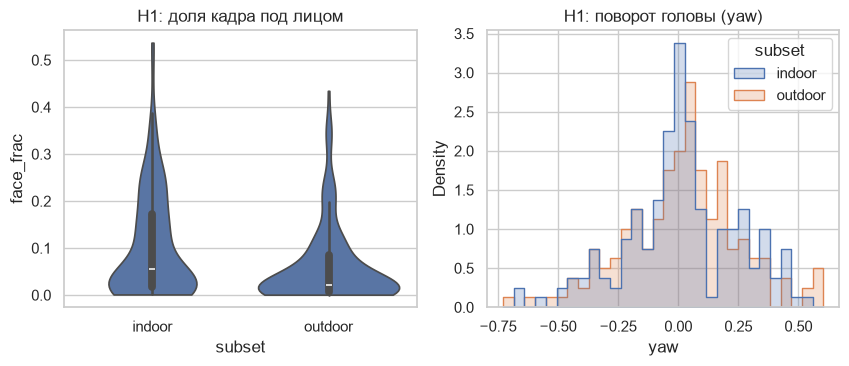

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sns.violinplot(data=feat, x="subset", y="face_frac", ax=axes[0], cut=0)
axes[0].set_title("H1: доля кадра под лицом")
sns.histplot(data=feat, x="yaw", hue="subset", bins=30, element="step", stat="density",
             common_norm=False, ax=axes[1])
axes[1].set_title("H1: поворот головы (yaw)")
save(fig, "10_h1.png")

**H1 подтверждается частично.** На outdoor лицо действительно занимает меньшую долю кадра
(медиана 2.2% против 5.5%, p = 3.4e-6, r = −0.27, эффект небольшой–средний). Но причина в том, что outdoor-кадры
крупнее, IOD в пикселях почти одинаковый (85 против 96). Разброс поворота головы не отличается:
std yaw 0.235 в обеих группах, Левене p = 0.95.

### H2. Индексы пропорций не зависят от условий съемки

In [29]:
rows = []
for c in ("nose_idx", "mouth_idx"):
    t = stats.mannwhitneyu(ind[c], outd[c])
    # бутстреп ДИ разницы медиан, чтобы говорить не только «не отвергли»
    boot = [np.median(rng.choice(outd[c], len(outd))) - np.median(rng.choice(ind[c], len(ind)))
            for _ in range(5000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({"индекс": c, "мед. indoor": ind[c].median(), "мед. outdoor": outd[c].median(),
                 "p (М-У)": t.pvalue, "r": rank_biserial(outd[c], ind[c]),
                 "ДИ95 разницы": f"[{lo:.3f}; {hi:.3f}]",
                 "CV indoor": cv(ind[c]), "CV outdoor": cv(outd[c])})
    results.append(("H2", f"{c}: indoor = outdoor", "Манн-Уитни", t.pvalue,
                    f"r={rank_biserial(outd[c], ind[c]):.3f}"))
h2 = pd.DataFrame(rows).set_index("индекс")
h2

,мед. indoor,мед. outdoor,p (М-У),r,ДИ95 разницы,CV indoor,CV outdoor
индекс,,,,,,,
nose_idx,0.544,0.548,0.725,-0.021,[-0.016; 0.028],0.149,0.135
mouth_idx,0.929,0.950,0.602,0.032,[-0.031; 0.058],0.163,0.160


In [30]:
# для сравнения: CV признаков, которые от съемки зависят
pd.Series({c: cv(feat[c]) for c in ("nose_idx", "mouth_idx", "face_frac", "iod_px", "face_px")},
          name="CV по всему набору").round(3)

nose_idx     0.142
mouth_idx    0.161
face_frac    1.226
iod_px       0.624
face_px      0.594
Name: CV по всему набору, dtype: float64

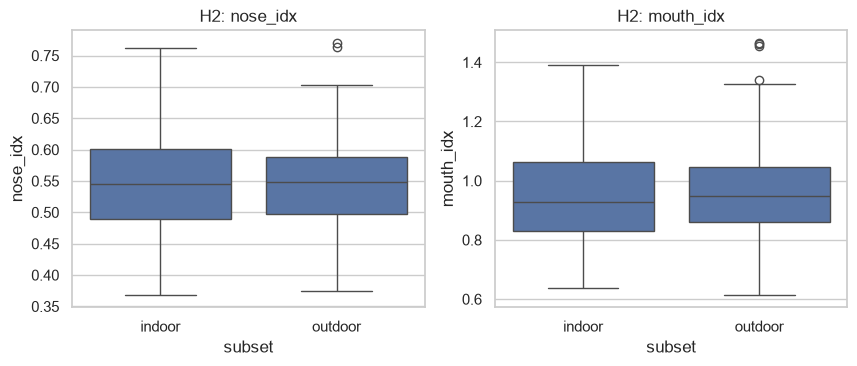

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for a, c in zip(axes, ("nose_idx", "mouth_idx")):
    sns.boxplot(data=feat, x="subset", y=c, ax=a)
    a.set_title(f"H2: {c}")
save(fig, "11_h2.png")

**H2 не опровергнута.** Разницы между indoor и outdoor нет: индекс носа p = 0.72 (r = −0.02), индекс рта p = 0.60.
Бутстреп-ДИ разницы медиан индекса носа [−0.016; 0.028], то есть в пределах ±5% от среднего (0.546).
Коэффициент вариации индексов 0.14–0.16, а у признаков съемки (доля кадра, IOD в px) 0.6–1.2.
Индексы можно считать устойчивой характеристикой лица (с оговоркой, что «не отвергли» ≠ «доказали равенство»).

### H3. При повороте головы индекс ширины носа искажается

In [32]:
rho, p = stats.spearmanr(feat.abs_yaw, feat.nose_idx)
rho_m, p_m = stats.spearmanr(feat.abs_yaw, feat.mouth_idx)
print(f"Спирмен |yaw| ~ nose_idx: rho={rho:.3f}, p={p:.2e}")
print(f"Спирмен |yaw| ~ mouth_idx: rho={rho_m:.3f}, p={p_m:.2e}")
results += [("H3", "|yaw| ~ nose_idx", "Спирмен", p, f"rho={rho:.3f}"),
            ("H3", "|yaw| ~ mouth_idx", "Спирмен", p_m, f"rho={rho_m:.3f}")]

bins = [0, 0.05, 0.10, 0.20, 0.30, np.inf]
feat["yaw_bin"] = pd.cut(feat.abs_yaw, bins, right=False)
feat.groupby("yaw_bin", observed=True)["nose_idx"].agg(["count", "median", "mean", "std"])

Спирмен |yaw| ~ nose_idx: rho=0.204, p=9.54e-05
Спирмен |yaw| ~ mouth_idx: rho=-0.001, p=9.90e-01


,count,median,mean,std
yaw_bin,,,,
"[0.0, 0.05)",97,0.524,0.532,0.083
"[0.05, 0.1)",54,0.527,0.528,0.074
"[0.1, 0.2)",75,0.562,0.549,0.067
"[0.2, 0.3)",56,0.552,0.551,0.072
"[0.3, inf)",78,0.558,0.569,0.082


In [33]:
frontal = feat.abs_yaw < 0.10
t = stats.mannwhitneyu(feat.nose_idx[frontal], feat.nose_idx[~frontal])
print(f"фронтальных (|yaw|<0.10): {frontal.sum()}, остальных: {(~frontal).sum()}")
print(f"nose_idx медианы: {feat.nose_idx[frontal].median():.3f} vs {feat.nose_idx[~frontal].median():.3f}, "
      f"p={t.pvalue:.2e}, r={rank_biserial(feat.nose_idx[~frontal], feat.nose_idx[frontal]):.3f}")
results.append(("H3", "nose_idx: |yaw|<0.1 vs >=0.1", "Манн-Уитни", t.pvalue,
                f"r={rank_biserial(feat.nose_idx[~frontal], feat.nose_idx[frontal]):.3f}"))

фронтальных (|yaw|<0.10): 151, остальных: 209
nose_idx медианы: 0.526 vs 0.554, p=8.09e-04, r=0.207


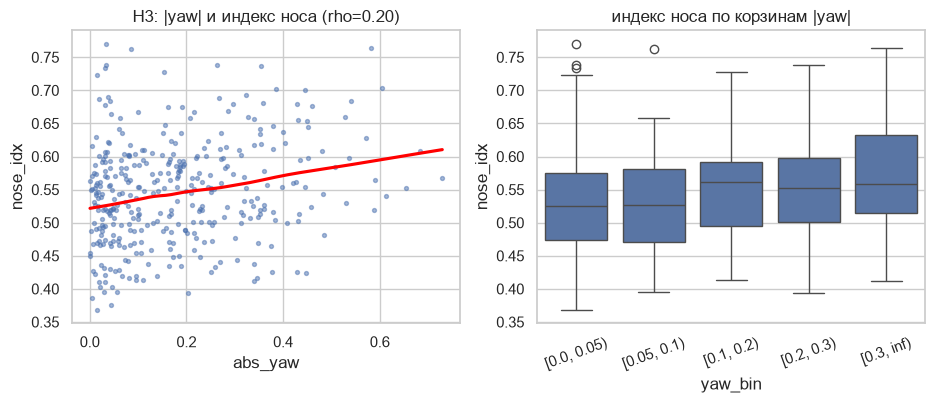

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.regplot(data=feat, x="abs_yaw", y="nose_idx", lowess=True, ax=axes[0],
            scatter_kws={"s": 8, "alpha": 0.5}, line_kws={"color": "red"})
axes[0].set_title(f"H3: |yaw| и индекс носа (rho={rho:.2f})")
sns.boxplot(data=feat, x="yaw_bin", y="nose_idx", ax=axes[1])
axes[1].set_title("индекс носа по корзинам |yaw|")
axes[1].tick_params(axis="x", rotation=20)
save(fig, "12_h3.png")

**H3 подтверждается.** С ростом |yaw| индекс носа растет (rho = 0.20, p = 9.5e-5): медиана 0.524 у фронтальных
(|yaw| < 0.05) и 0.558 при |yaw| ≥ 0.3, то есть завышение примерно на 6%. Межзрачковое при повороте
сжимается сильнее, чем ширина носа. Индекс рта от поворота не зависит (rho ≈ 0).
Для отчета специалисту нужны фронтальные снимки, порог |yaw| < 0.10 (таких 151 из 360).

### H4 (своя). Открытый рот / улыбка меняют индекс ширины рта

Спирмен mouth_open ~ mouth_idx: rho=0.342, p=2.65e-11
рот закрыт (<0.05 IOD): 124, открыт: 236
mouth_idx медианы: закрыт 0.882, открыт 0.984, p=1.13e-08, r=0.366


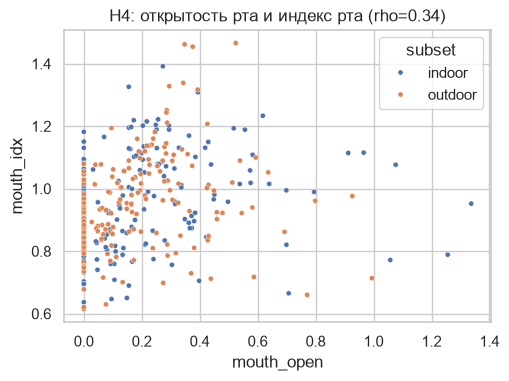

In [35]:
rho4, p4 = stats.spearmanr(feat.mouth_open, feat.mouth_idx)
closed = feat.mouth_open < 0.05
t4 = stats.mannwhitneyu(feat.mouth_idx[~closed], feat.mouth_idx[closed])
print(f"Спирмен mouth_open ~ mouth_idx: rho={rho4:.3f}, p={p4:.2e}")
print(f"рот закрыт (<0.05 IOD): {closed.sum()}, открыт: {(~closed).sum()}")
print(f"mouth_idx медианы: закрыт {feat.mouth_idx[closed].median():.3f}, "
      f"открыт {feat.mouth_idx[~closed].median():.3f}, p={t4.pvalue:.2e}, "
      f"r={rank_biserial(feat.mouth_idx[~closed], feat.mouth_idx[closed]):.3f}")
results += [("H4", "mouth_open ~ mouth_idx", "Спирмен", p4, f"rho={rho4:.3f}"),
            ("H4", "mouth_idx: открыт vs закрыт", "Манн-Уитни", t4.pvalue,
             f"r={rank_biserial(feat.mouth_idx[~closed], feat.mouth_idx[closed]):.3f}")]

fig, ax = plt.subplots(figsize=(5.5, 3.8))
sns.scatterplot(data=feat, x="mouth_open", y="mouth_idx", hue="subset", s=14, ax=ax)
ax.set_title(f"H4: открытость рта и индекс рта (rho={rho4:.2f})")
save(fig, "13_h4.png")

**H4 подтверждается.** Открытый рот (улыбка, речь) растягивает рот: rho = 0.34, p = 2.6e-11; медиана индекса
рта 0.88 с закрытым ртом против 0.98 с открытым (+12%, r = 0.37). Индекс рта имеет смысл только при
нейтральном выражении, в требования к фото надо добавить «рот закрыт» (mouth_open < 0.05).

### Сводка тестов (с поправкой Холма на множественные сравнения)

In [36]:
res =pd.DataFrame(results, columns=["гипотеза", "проверка", "тест", "p", "эффект"])
order = res.p.argsort()
m = len(res)
holm = np.maximum.accumulate((m - np.arange(m)) * res.p.to_numpy()[order]).clip(max=1)
res.loc[res.index[order], "p_holm"] = holm
res["значимо (0.05)"] = res.p_holm < 0.05
res

,гипотеза,проверка,тест,p,эффект,p_holm,значимо (0.05)
0,H1,face_frac outdoor < indoor,Манн-Уитни,3.434e-06,r=-0.274,2.404e-05,True
1,H1,разброс yaw outdoor > indoor,Левене,9.466e-01,std ratio=1.00,1.000e+00,False
2,H2,nose_idx: indoor = outdoor,Манн-Уитни,7.249e-01,r=-0.021,1.000e+00,False
3,H2,mouth_idx: indoor = outdoor,Манн-Уитни,6.016e-01,r=0.032,1.000e+00,False
4,H3,|yaw| ~ nose_idx,Спирмен,9.542e-05,rho=0.204,5.725e-04,True
5,H3,|yaw| ~ mouth_idx,Спирмен,9.903e-01,rho=-0.001,1.000e+00,False
6,H3,nose_idx: |yaw|<0.1 vs >=0.1,Манн-Уитни,8.085e-04,r=0.207,4.043e-03,True
7,H4,mouth_open ~ mouth_idx,Спирмен,2.646e-11,rho=0.342,2.382e-10,True
8,H4,mouth_idx: открыт vs закрыт,Манн-Уитни,1.130e-08,r=0.366,9.041e-08,True


## Выводы

1. Данные чистые по форме (без пропусков, дублей строк, перепутанных сторон), но 135 из 360 снимков —
   это 53 фото с несколькими размеченными лицами. Разбиение делать по группам фото.
2. Точки за кадром — 5 снимков, до 1.5 px, лечится обрезкой. Маленьких лиц (IOD < 40 px) 20 штук.
3. Рамку лица по точкам в модель не подавать: это утечка, занижает NME (0.35 против 0.51 при шуме 10%).
   subset в признаки не брать.
4. Индексы пропорций от условий съемки не зависят (H2), но зависят от позы и мимики:
   поворот завышает индекс носа примерно на 6% (H3), открытый рот — индекс рта на 12% (H4).
   Отсюда требования к фото: |yaw| < 0.10 и закрытый рот, иначе отчет помечается как ненадежный.
5. Индекс асимметрии в нынешнем виде меряет поворот (rho = 0.91 с yaw), его надо считать после
   выравнивания позы или только на фронтальных снимках.